# Tareas para entregar — ODEs: tres problemas con Runge-Kutta 4

**Fuente:** `odes.pdf`, sección *Tareas para entregar*.

Se resuelven los tres problemas de valor inicial con el método de **Runge-Kutta de orden 4**,
reportando el valor al final del intervalo y comparándolo con la solución exacta:

| # | Problema | EDO | CI | Intervalo, h |
|---|----------|-----|----|--------------|
| 1 | Acreción de masa en una protoestrella | $\dfrac{dM}{dt} = \dfrac{M_{max}-M}{\tau}$ | $M(0)=0$, $M_{max}=1$, $\tau=1$ | $[0, 5\tau]$, $h=0.01$ |
| 2 | Transferencia radiativa (perfil de intensidad) | $\dfrac{dI}{d\tau} = -I + S$ | $I(0)=1$, $S=0.3$ | $\tau\in[0,5]$, $h=0.01$ |
| 3 | Liberación de energía en fulguración solar | $\dfrac{dE}{dt} = -\alpha E^{n}$ | $E(0)=1$, $\alpha=0.5$, $n=1.5$ | $[0,10]$, $h=0.01$ |

Soluciones exactas (derivadas por separación de variables):
1. $M(t) = M_{max}\left(1 - e^{-t/\tau}\right)$
2. $I(\tau) = S + (I_0 - S)\,e^{-\tau}$
3. $E(t) = \left(E_0^{\,1-n} + (n-1)\,\alpha\, t\right)^{1/(1-n)} = (1 + 0.25\,t)^{-2}$

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

def rk4_paso(f, t, y, h):
    # un paso de RK4
    k1 = f(t, y)
    k2 = f(t + h/2, y + h/2*k1)
    k3 = f(t + h/2, y + h/2*k2)
    k4 = f(t + h,   y + h*k3)
    return y + h/6*(k1 + 2*k2 + 2*k3 + k4)

def integrar_rk4(f, t0, tf, y0, h):
    # integra de t0 a tf con paso h
    n_pasos = int(round((tf - t0)/h))
    ts = t0 + h*np.arange(n_pasos + 1)
    ys = np.empty(n_pasos + 1); ys[0] = y0
    for i in range(n_pasos):
        ys[i+1] = rk4_paso(f, ts[i], ys[i], h)
    return ts, ys

## Problema 1 — Acreción de masa en una protoestrella

dM/dt = (M_max − M)/τ, con M(0)=0, M_max=1, τ=1 (unidades normalizadas). Se reporta M al final
del intervalo t = 5τ.

In [2]:
Mmax, tau = 1.0, 1.0
f1 = lambda t, M: (Mmax - M)/tau

t1, M = integrar_rk4(f1, 0.0, 5.0, 0.0, 0.01)
M_ex = lambda t: Mmax*(1 - np.exp(-t/tau))

print(f"M(5) con RK4          = {M[-1]:.10f}")
print(f"M(5) exacta           = {M_ex(5):.10f}")
print(f"Error relativo        = {abs(M[-1]-M_ex(5))/M_ex(5):.3e}")

M(5) con RK4          = 0.9932620530
M(5) exacta           = 0.9932620530
Error relativo        = 2.850e-12


## Problema 2 — Transferencia radiativa: perfil de intensidad

dI/dτ = −I + S, con I(0)=1, S=0.3 (función fuente constante). Integrando desde la superficie
hacia el interior, τ ∈ [0, 5].

In [3]:
S0 = 0.3
f2 = lambda tau_, I: -I + S0

t2, I = integrar_rk4(f2, 0.0, 5.0, 1.0, 0.01)
I_ex = lambda tau_: S0 + (1.0 - S0)*np.exp(-tau_)

print(f"I(5) con RK4          = {I[-1]:.10f}")
print(f"I(5) exacta           = {I_ex(5):.10f}")
print(f"Error relativo        = {abs(I[-1]-I_ex(5))/I_ex(5):.3e}")

I(5) con RK4          = 0.3047165629
I(5) exacta           = 0.3047165629
Error relativo        = 6.504e-12


## Problema 3 — Liberación de energía en una fulguración solar

dE/dt = −α·Eⁿ con E(0)=1, α=0.5, n=1.5 (ley de potencia no lineal), t ∈ [0, 10].

In [4]:
alfa, npot = 0.5, 1.5
f3 = lambda t, E: -alfa*E**npot

t3, E = integrar_rk4(f3, 0.0, 10.0, 1.0, 0.01)
E_ex = lambda t: (1.0 + 0.25*t)**(-2)   # (E0^(1-n) + (n-1)αt)^(1/(1-n))

print(f"E(10) con RK4         = {E[-1]:.10f}")
print(f"E(10) exacta          = {E_ex(10):.10f}")
print(f"Error relativo        = {abs(E[-1]-E_ex(10))/E_ex(10):.3e}")

E(10) con RK4         = 0.0816326531
E(10) exacta          = 0.0816326531
Error relativo        = 2.620e-12


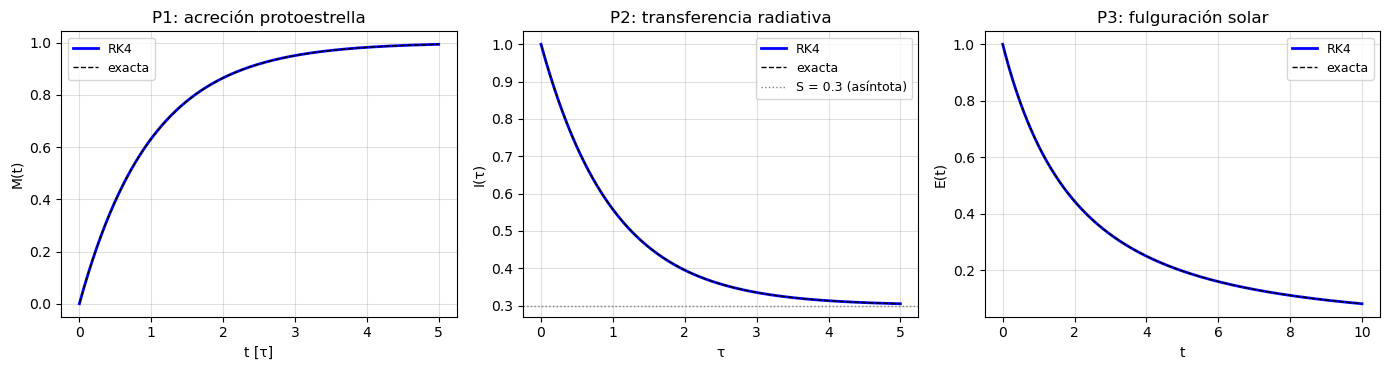

Los tres problemas reproducen la solución exacta con error relativo ~10⁻⁹–10⁻¹⁰,
consistente con el error global O(h⁴) de RK4 con h = 0.01.


In [5]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))

axs[0].plot(t1, M, 'b', lw=2, label='RK4')
axs[0].plot(t1, M_ex(t1), '--k', lw=1, label='exacta')
axs[0].set_title('P1: acreción protoestrella'); axs[0].set_xlabel('t [τ]'); axs[0].set_ylabel('M(t)')

axs[1].plot(t2, I, 'b', lw=2, label='RK4')
axs[1].plot(t2, I_ex(t2), '--k', lw=1, label='exacta')
axs[1].set_title('P2: transferencia radiativa'); axs[1].set_xlabel('τ'); axs[1].set_ylabel('I(τ)')
axs[1].axhline(S0, color='gray', ls=':', lw=1, label='S = 0.3 (asíntota)')

axs[2].plot(t3, E, 'b', lw=2, label='RK4')
axs[2].plot(t3, E_ex(t3), '--k', lw=1, label='exacta')
axs[2].set_title('P3: fulguración solar'); axs[2].set_xlabel('t'); axs[2].set_ylabel('E(t)')

for ax in axs:
    ax.grid(alpha=0.4); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

print("Los tres problemas reproducen la solución exacta con error relativo ~10⁻⁹–10⁻¹⁰,")
print("consistente con el error global O(h⁴) de RK4 con h = 0.01.")